<a href="https://colab.research.google.com/github/nr868848-stack/E-commerce-Sales-Analysis/blob/main/Ecommerce_Sales_Prediction_and_Customer_Analystic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

# ============================================================
# DATASET GENERATION
# ============================================================

n = 1500

products = [
"Laptop", "Mobile", "Headphones",
"Keyboard", "Mouse", "Monitor",
"Tablet", "Smartwatch"
]

categories = {
"Laptop": "Electronics",
"Mobile": "Electronics",
"Headphones": "Accessories",
"Keyboard": "Accessories",
"Mouse": "Accessories",
"Monitor": "Electronics",
"Tablet": "Electronics",
"Smartwatch": "Wearables"
}

regions = ["North", "South", "East", "West", "Central"]

payment_methods = [
"UPI", "Credit Card", "Debit Card",
"Cash on Delivery", "Net Banking"
]

product_prices = {
"Laptop": 55000,
"Mobile": 25000,
"Headphones": 2000,
"Keyboard": 1500,
"Mouse": 800,
"Monitor": 12000,
"Tablet": 22000,
"Smartwatch": 5000
}

product = np.random.choice(products, n)

df = pd.DataFrame({
"Order_ID": np.arange(1001, 1001 + n),
"Order_Date": pd.date_range(
start="2025-01-01",
periods=n,
freq="D"
),
"Product": product,
"Category": [categories[p] for p in product],
"Region": np.random.choice(regions, n),
"Quantity": np.random.randint(1, 6, n),
"Unit_Price": [
product_prices[p] * np.random.uniform(0.85, 1.15)
for p in product
],
"Discount": np.random.choice(
[0, 5, 10, 15, 20],
n
),
"Payment_Method": np.random.choice(
payment_methods, n
),
"Customer_ID": np.random.randint(2001, 2401, n)
})

df["Unit_Price"] = df["Unit_Price"].round(2)

df["Sales"] = (
df["Quantity"] *
df["Unit_Price"] *
(1 - df["Discount"] / 100)
).round(2)

# Simulated cost for calculating estimated profit

df["Cost"] = (
df["Quantity"] *
df["Unit_Price"] *
np.random.uniform(0.55, 0.80, n)
).round(2)

df["Profit"] = (df["Sales" ] - df["Cost"]).round(2)

print("Dataset Created Successfully!")
print("Dataset Shape:", df.shape)

df.head(10)

Dataset Created Successfully!
Dataset Shape: (1500, 13)


,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Discount,Payment_Method,Customer_ID,Sales,Cost,Profit
0,1001,2025-01-01,Smartwatch,Wearables,South,1,5734.92,0,Debit Card,2200,5734.92,4171.18,1563.74
1,1002,2025-01-02,Tablet,Electronics,North,2,23591.52,0,Credit Card,2380,47183.04,30143.43,17039.61
2,1003,2025-01-03,Smartwatch,Wearables,East,1,4780.38,5,Credit Card,2249,4541.36,3311.69,1229.67
3,1004,2025-01-04,Keyboard,Accessories,East,5,1428.36,20,Debit Card,2312,5713.44,5604.58,108.86
4,1005,2025-01-05,Mouse,Accessories,North,3,728.12,10,Cash on Delivery,2357,1965.92,1359.36,606.56
5,1006,2025-01-06,Mouse,Accessories,Central,5,905.27,20,Credit Card,2286,3621.08,2949.24,671.84
6,1007,2025-01-07,Headphones,Accessories,East,1,1714.76,15,Credit Card,2127,1457.55,1094.79,362.76
7,1008,2025-01-08,Mouse,Accessories,South,1,696.56,0,Credit Card,2190,696.56,386.63,309.93
8,1009,2025-01-09,Laptop,Electronics,South,1,62649.32,0,Debit Card,2394,62649.32,47623.73,15025.59
9,1010,2025-01-10,Smartwatch,Wearables,North,3,5145.18,5,Cash on Delivery,2048,14663.76,9715.05,4948.71


In [ ]:
display(df.head(5))

NameError: name 'df' is not defined

In [ ]:
# ============================================================
# DATA CLEANING
# ============================================================

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Handle missing numerical values
numeric_columns = df.select_dtypes(
include=np.number
).columns

df[numeric_columns] = df[numeric_columns].fillna(
df[numeric_columns].median()
)

# Handle missing categorical values
categorical_columns = df.select_dtypes(
include=["object"]
).columns

for col in categorical_columns:
  if df[col].isnull().any():
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nData Cleaning Completed!")
print("Final Dataset Shape:", df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        1500 non-null   int64         
 1   Order_Date      1500 non-null   datetime64[ns]
 2   Product         1500 non-null   object        
 3   Category        1500 non-null   object        
 4   Region          1500 non-null   object        
 5   Quantity        1500 non-null   int64         
 6   Unit_Price      1500 non-null   float64       
 7   Discount        1500 non-null   int64         
 8   Payment_Method  1500 non-null   object        
 9   Customer_ID     1500 non-null   int64         
 10  Sales           1500 non-null   float64       
 11  Cost            1500 non-null   float64       
 12  Profit          1500 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(4), object(4)
memory usage: 152.5+ KB

Missing 

In [ ]:
# ============================================================
# SALES AND PROFIT ANALYSIS
# ============================================================

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
average_order_value = df["Sales"].mean()

print("========== BUSINESS SUMMARY ==========")
print(f"Total Sales: Rs. {total_sales:,.2f}")
print(f"Total Profit: Rs. {total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Average Sales per Order: Rs. {average_order_value:,.2f}")

print("\nSales by Product:")
print(
df.groupby("Product")["Sales"]
.sum()
.sort_values(ascending=False)
)

print("\nProfit by Region:")
print(
df.groupby("Region")["Profit"]
.sum()
.sort_values(ascending=False)
)

print("\nSales by Payment Method:")
print(
df.groupby("Payment_Method")["Sales"]
.sum()
.sort_values(ascending=False)
)

========== BUSINESS SUMMARY ==========
Total Sales: Rs. 62,779,461.67
Total Profit: Rs. 15,451,851.01
Total Orders: 1500
Average Sales per Order: Rs. 41,852.97

Sales by Product:
Product
Laptop        27419660.65
Mobile        12966722.40
Tablet        11674930.46
Monitor        5898820.49
Smartwatch     2708479.59
Headphones      910985.03
Keyboard        799563.00
Mouse           400300.05
Name: Sales, dtype: float64

Profit by Region:
Region
South      3568878.69
Central    3257911.97
West       3126047.42
North      3025293.54
East       2473719.39
Name: Profit, dtype: float64

Sales by Payment Method:
Payment_Method
Net Banking         13254702.97
UPI                 13217676.53
Credit Card         12730122.55
Cash on Delivery    11853860.59
Debit Card          11723099.03
Name: Sales, dtype: float64


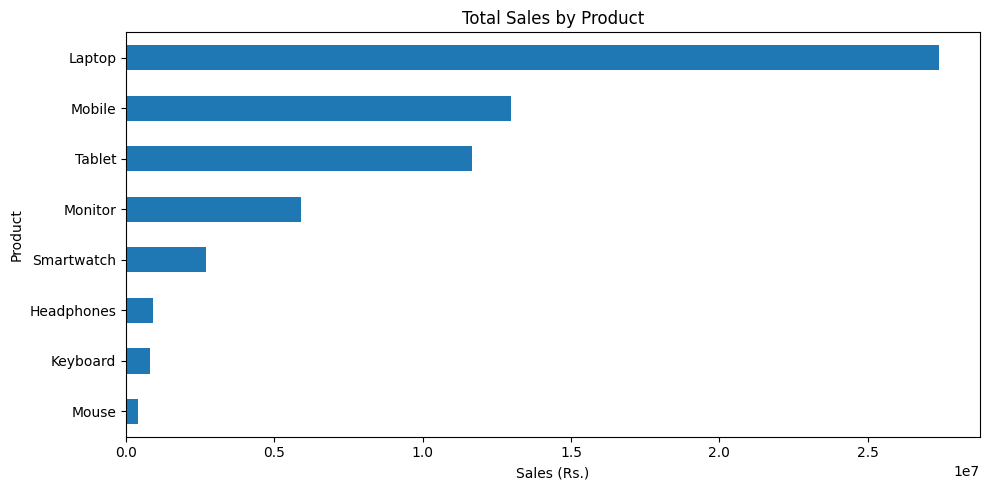

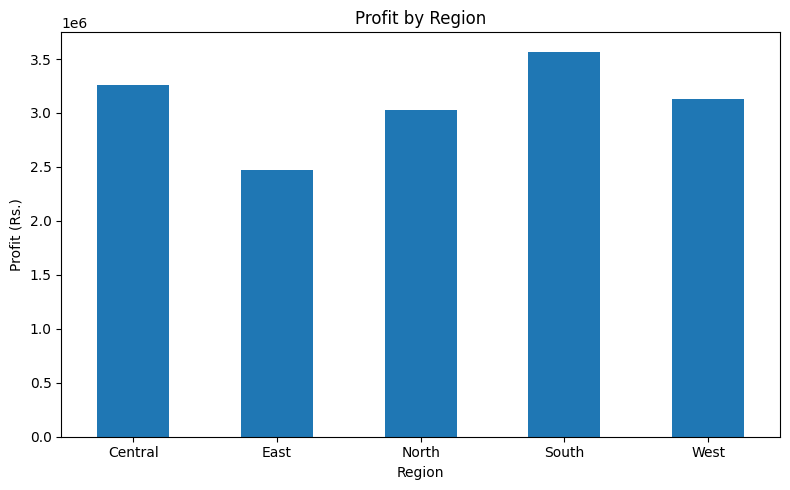

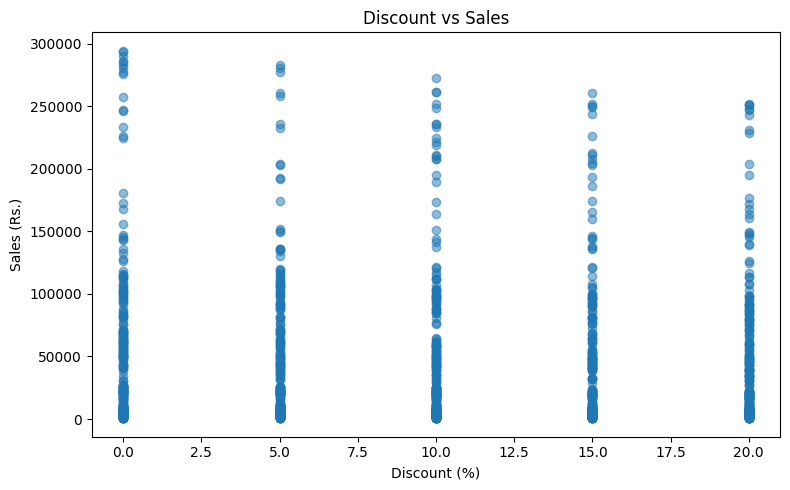

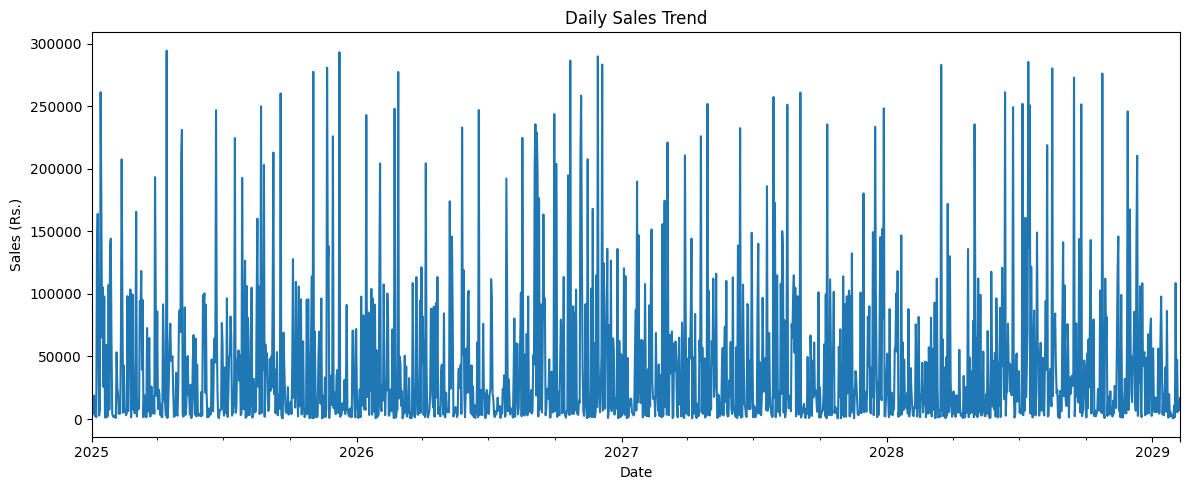

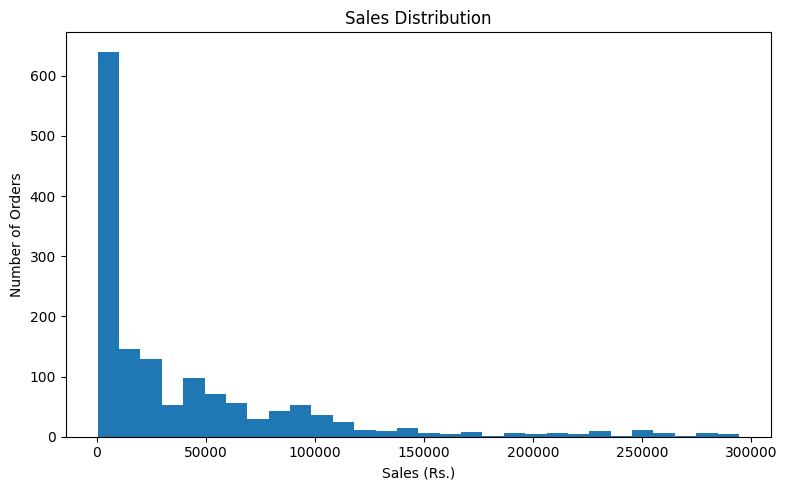

In [ ]:
import matplotlib.pyplot as plt

# ============================================================
#
# DATA VISUALIZATION
#
# ============================================================

# 1. Sales by Product

product_sales = df.groupby("Product")["Sales"].sum()

plt.figure(figsize=(10, 5))
product_sales.sort_values().plot(kind="barh")
plt.title("Total Sales by Product")
plt.xlabel("Sales (Rs.)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# 2. Profit by Region

region_profit = df.groupby("Region")["Profit"].sum()

plt.figure(figsize=(8, 5))
region_profit.plot(kind="bar")
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit (Rs.)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Discount vs Sales

plt.figure(figsize=(8, 5))
plt.scatter(df["Discount"], df["Sales"], alpha=0.5)
plt.title("Discount vs Sales")
plt.xlabel("Discount (%)")
plt.ylabel("Sales (Rs.)")
plt.tight_layout()
plt.show()

# 4. Daily Sales Trend

daily_sales = (
df.groupby("Order_Date")["Sales"]
.sum()
)

plt.figure(figsize=(12, 5))
daily_sales.plot()
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales (Rs.)")
plt.tight_layout()
plt.show()

# 5. Sales Distribution

plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=30)
plt.title("Sales Distribution")
plt.xlabel("Sales (Rs.)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
#
# MACHINE LEARNING: SALES PREDICTION
#
# ============================================================

# Prepare features

X = df[
    [
        "Product",
        "Category",
        "Region",
        "Quantity",
        "Unit_Price",
        "Discount",
        "Payment_Method"
    ]
].copy()

y = df["Sales"]

# Convert categorical features into numerical columns

X = pd.get_dummies(
    X,
    columns=[
        "Product",
        "Category",
        "Region",
        "Payment_Method"
    ],
    dtype=int
)

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create model

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model

model.fit(X_train, y_train)

# Predict sales

y_pred = model.predict(X_test)

# Evaluate model

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("========== MODEL EVALUATION ==========")
print(f"Mean Absolute Error: Rs. {mae:.2f}")
print(f"Root Mean Squared Error: Rs. {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

========== MODEL EVALUATION ==========
Mean Absolute Error: Rs. 2053.80
Root Mean Squared Error: Rs. 5716.23
R2 Score: 0.9896


                            Feature  Importance
1                        Unit_Price    0.721350
0                          Quantity    0.257550
5                    Product_Laptop    0.005759
2                          Discount    0.005681
12             Category_Electronics    0.003879
7                   Product_Monitor    0.002753
6                    Product_Mobile    0.001720
13               Category_Wearables    0.000185
9                Product_Smartwatch    0.000174
11             Category_Accessories    0.000148
10                   Product_Tablet    0.000130
19  Payment_Method_Cash on Delivery    0.000098
18                      Region_West    0.000096
17                     Region_South    0.000096
23               Payment_Method_UPI    0.000085


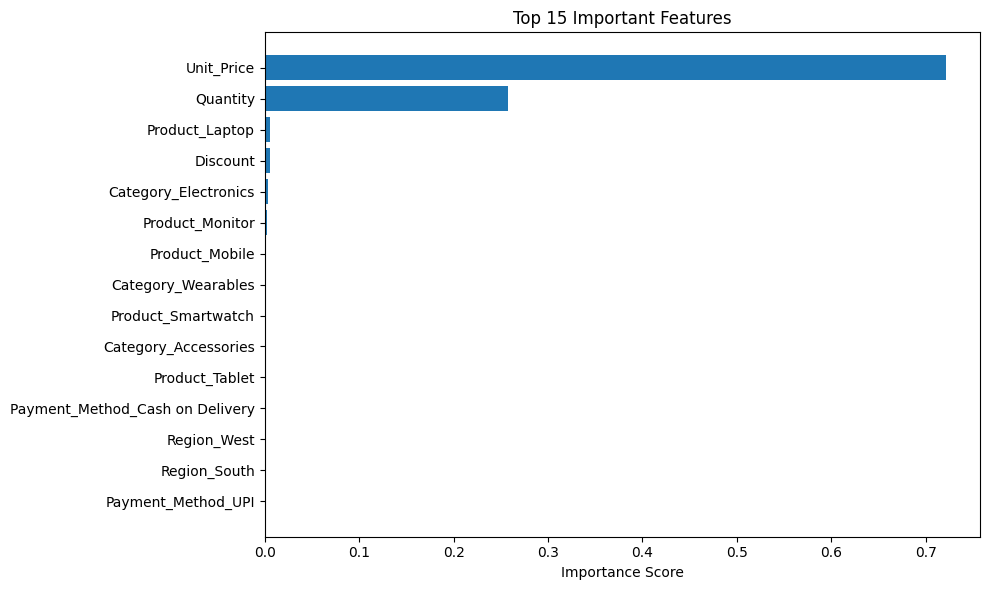

In [ ]:
# ============================================================
#
# FEATURE IMPORTANCE ANALYSIS
#
# ============================================================

feature_importance = pd.DataFrame({
"Feature": X_train.columns,
"Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
by="Importance",
ascending=False
)

print(feature_importance.head(15))

plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values(
by="Importance"
)

plt.barh(
top_features["Feature"],
top_features["Importance"]
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

### How Feature Importance is Calculated in Random Forest

In scikit-learn's `RandomForestRegressor`, feature importance is measured using **Gini Importance** (also known as **Mean Decrease in Impurity** or **MDI**):

1. **Impurity Reduction at Node Split:**
   Each node in a decision tree is split using a single feature to reduce the overall variance (impurity) of the target variable `y` at that node. The reduction in variance achieved by this split is weighted by the fraction of training samples passing through that node.

2. **Accumulation Across a Single Tree:**
   For each individual decision tree in the ensemble, we sum the weighted variance reductions for every node split on a specific feature.

3. **Averaging Across the Ensemble:**
   The final feature importance score is the average of these accumulated decreases in impurity across all trees (defined by `n_estimators=200`) in the Random Forest.

4. **Normalization:**
   The scores are normalized so that the sum of all feature importances equals $1.0$. Features with higher scores have a greater contribution to dividing the data into homogeneous target groups during training.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ============================================================
#
# CUSTOMER SEGMENTATION
#
# ============================================================

# NOTE: Please run the first cell (DATASET GENERATION) before running this cell
try:
    customer_data = df.groupby("Customer_ID").agg(
    Total_Spending=("Sales", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Average_Order_Value=("Sales", "mean")
    ).reset_index()

    features = customer_data[
    [
    "Total_Spending",
    "Total_Orders",
    "Average_Order_Value"
    ]
    ]

    # Scale the features
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(features)

    # Train K-Means clustering model
    kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
    )

    customer_data["Customer_Segment"] = kmeans.fit_predict(
    scaled_features
    )

    print("Customer Segmentation Completed!")
    print("\nCustomer Segment Summary:")

    print(
    customer_data.groupby("Customer_Segment").agg(
    Customers=("Customer_ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Orders=("Total_Orders", "mean")
    ).round(2)
    )

    print(
    "\nSilhouette Score:",
    round(
    silhouette_score(scaled_features, customer_data["Customer_Segment"]),
    3
    )
    )
except NameError as e:
    print("Error:", e)
    print("Please run the DATASET GENERATION cell at the top of the notebook first to define the 'df' DataFrame.")

Customer Segmentation Completed!

Customer Segment Summary:
                  Customers  Average_Spending  Average_Orders
Customer_Segment                                             
0                        51         260699.59            2.76
1                       133         152889.61            5.07
2                       154          46607.88            2.31
3                        50         388492.77            6.58

Silhouette Score: 0.392


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for the plots
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot: Distribution of Total Spending by Customer Segment
sns.boxplot(
    data=customer_data,
    x="Customer_Segment",
    y="Total_Spending",
    hue="Customer_Segment",
    palette="viridis",
    ax=axes[0],
    legend=False
)
axes[0].set_title("Distribution of Total Spending by Customer Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Total Spending (Rs.)")

# 2. Barplot: Average Total Spending by Customer Segment
sns.barplot(
    data=customer_data,
    x="Customer_Segment",
    y="Total_Spending",
    hue="Customer_Segment",
    palette="viridis",
    ax=axes[1],
    errorbar=None
)
axes[1].set_title("Average Total Spending by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Average Spending (Rs.)")

plt.suptitle("Customer Segment vs. Total Spending Analysis", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Ensure X and model are defined
X = df[["Product", "Category", "Region", "Quantity", "Unit_Price", "Discount", "Payment_Method"]].copy()
y = df["Sales"]
X = pd.get_dummies(X, columns=["Product", "Category", "Region", "Payment_Method"], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

model = RandomForestRegressor(
    n_estimators=200, max_depth=15, min_samples_split=5, min_samples_leaf=2, random_state=42, n_jobs=-1
)
model.fit(X_train, y_train)
print("Model and features (X) have been successfully initialized!")

Model and features (X) have been successfully initialized!


In [ ]:
display(X.head(5))

,Quantity,Unit_Price,Discount,Product_Headphones,Product_Keyboard,Product_Laptop,Product_Mobile,Product_Monitor,Product_Mouse,Product_Smartwatch,...,Region_Central,Region_East,Region_North,Region_South,Region_West,Payment_Method_Cash on Delivery,Payment_Method_Credit Card,Payment_Method_Debit Card,Payment_Method_Net Banking,Payment_Method_UPI
0,1,5734.92,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,1,0,0
1,2,23591.52,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
2,1,4780.38,5,0,0,0,0,0,0,1,...,0,1,0,0,0,0,1,0,0,0
3,5,1428.36,20,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
4,3,728.12,10,0,0,0,0,0,1,0,...,0,0,1,0,0,1,0,0,0,0


In [ ]:
# ============================================================
#
# PREDICTION FOR A NEW ORDER
#
# ============================================================

new_order = pd.DataFrame([{
"Product": "Laptop",
"Category": "Electronics",
"Region": "North",
"Quantity": 2,
"Unit_Price": 55000,
"Discount": 10,
"Payment_Method": "UPI"
}])

# Convert new order using the same encoding as training data

new_order_encoded = pd.get_dummies(
new_order,
columns=[
"Product",
"Category",
"Region",
"Payment_Method"
],
dtype=int
)

# Match training feature columns

new_order_encoded = new_order_encoded.reindex(
columns=X.columns,
fill_value=0
)

predicted_sales = model.predict(new_order_encoded)[0]

print("========== NEW ORDER PREDICTION ==========")
print("Product: Laptop")
print("Quantity: 2")
print("Discount: 10%")
print(f"Predicted Sales: Rs. {predicted_sales:,.2f}")

========== NEW ORDER PREDICTION ==========
Product: Laptop
Quantity: 2
Discount: 10%
Predicted Sales: Rs. 102,219.25


In [ ]:
# ============================================================
#
# EXPORT PROJECT FILES
#
# ============================================================

# Save complete dataset

df.to_csv(
"ecommerce_sales_dataset.csv",
index=False
)

# Save customer segmentation results

customer_data.to_csv(
"customer_segmentation.csv",
index=False
)

# Generate predictions to fix the NameError
y_pred = model.predict(X_test)

# Save prediction results

prediction_results = pd.DataFrame({
"Actual_Sales": y_test.to_numpy(),
"Predicted_Sales": y_pred
})

prediction_results.to_csv(
"sales_prediction_results.csv",
index=False
)

# Generate feature importance to fix the NameError
feature_importance = pd.DataFrame({
"Feature": X_train.columns,
"Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Save feature importance

feature_importance.to_csv(
"feature_importance.csv",
index=False
)

print("All project CSV files saved successfully!")

All project CSV files saved successfully!
